In [36]:
from sklearn.cluster import AgglomerativeClustering
import pandas as pd
from scipy.cluster.hierarchy import fcluster, dendrogram, linkage
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("student_exam_outcomes.csv")

In [5]:
df.head(10)

,study_hours_per_day,attendance_percent,assignment_completion_percent,sleep_hours,tutoring,previous_exam_score,passed
0,4.2,89.4,66,6.5,Yes,32.7,1
1,0.2,66.1,73,7.0,Yes,69.8,0
2,5.5,84.8,37,7.4,No,35.6,1
3,5.6,75.7,46,6.7,No,46.6,1
4,0.7,96.7,80,6.1,Yes,81.9,0
5,7.4,46.0,67,4.9,Yes,28.5,1
6,3.8,76.9,20,7.5,No,92.0,0
7,4.2,64.8,54,7.8,No,42.5,0
8,2.5,64.1,41,5.8,Yes,48.5,1
9,0.4,99.5,22,6.1,No,76.0,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   study_hours_per_day            400 non-null    float64
 1   attendance_percent             400 non-null    float64
 2   assignment_completion_percent  400 non-null    int64  
 3   sleep_hours                    400 non-null    float64
 4   tutoring                       400 non-null    str    
 5   previous_exam_score            400 non-null    float64
 6   passed                         400 non-null    int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 22.0 KB


In [6]:
X = df.drop("passed", axis=1)

In [15]:
scaler = StandardScaler()
encoder =  OneHotEncoder(handle_unknown="ignore", sparse_output=False)

In [16]:
numerical_col = X.select_dtypes(include="number").columns
categorical_col = X.select_dtypes(exclude="number").columns

In [18]:
X_scaled = scaler.fit_transform(df[numerical_col])
X_encoded = encoder.fit_transform(df[categorical_col])

In [20]:
X_processed = np.hstack([X_scaled, X_encoded])

In [23]:
AC_model = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0,
    linkage="ward"
)

label = AC_model.fit_predict(X_processed)

df["model_label"] = label

In [25]:
Z = linkage(X_processed, method="ward")

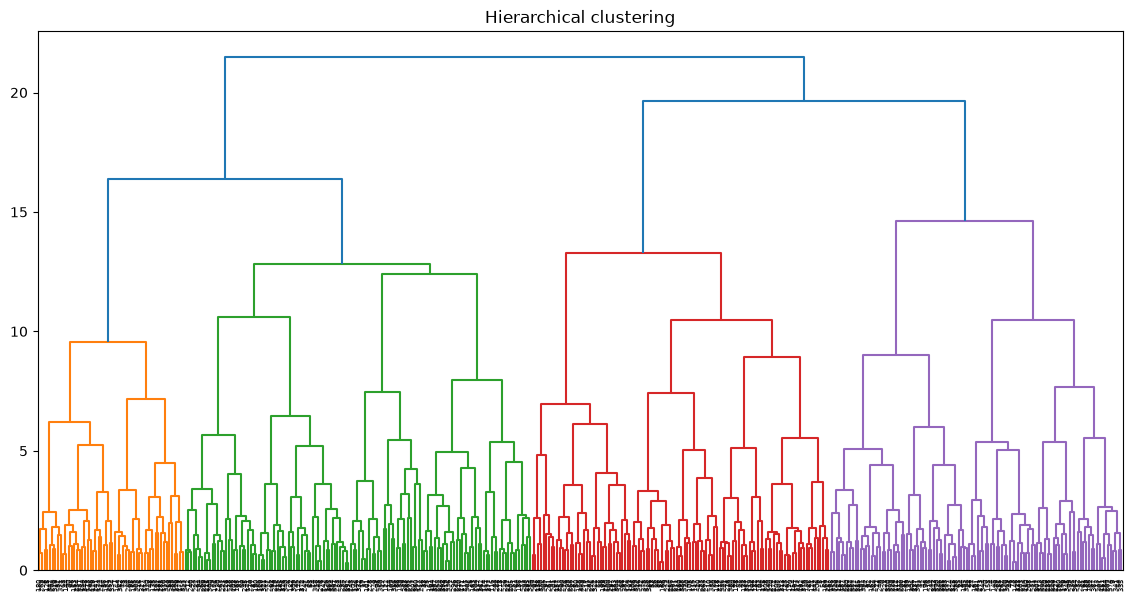

In [30]:
plt.figure(figsize=(14, 7))
dendrogram(Z)

plt.title("Hierarchical clustering")
plt.show()

In [35]:
hierarchical_cluster_17 = fcluster(
    Z,
    t=17,
    criterion="distance"
)
df["label_17"] = hierarchical_cluster_17
print("No. of clusters: ", len(set(hierarchical_cluster_17)))

hierarchical_cluster_21 = fcluster(
    Z,
    t=21,
    criterion="distance"
)
df["label_21"] = hierarchical_cluster_21
print("No. of clusters: ", len(set(hierarchical_cluster_21)))

hierarchical_cluster_16 = fcluster(
    Z,
    t=16,
    criterion="distance"
)
df["label_16"] = hierarchical_cluster_16
print("No. of clusters: ", len(set(hierarchical_cluster_16)))


No. of clusters:  3
No. of clusters:  2
No. of clusters:  4


In [37]:
for cluster, label in [
    (2, hierarchical_cluster_21),
    (3, hierarchical_cluster_17),
    (4, hierarchical_cluster_16)
]:
    print(f"\nFor cluster: {cluster}")

    print("silhouette_score: ", silhouette_score(X_processed, label))
    print("davies_bouldin_score: ", davies_bouldin_score(X_processed, label))
    print("calinski_harabasz_score: ", calinski_harabasz_score(X_processed, label))


For cluster: 2
silhouette_score:  0.10515593567123553
davies_bouldin_score:  2.826030433222996
calinski_harabasz_score:  46.6685039357435

For cluster: 3
silhouette_score:  0.09968363659682498
davies_bouldin_score:  2.3162716413523747
calinski_harabasz_score:  47.41003680139086

For cluster: 4
silhouette_score:  0.0964774235245131
davies_bouldin_score:  2.1701854504892015
calinski_harabasz_score:  44.920009694400996


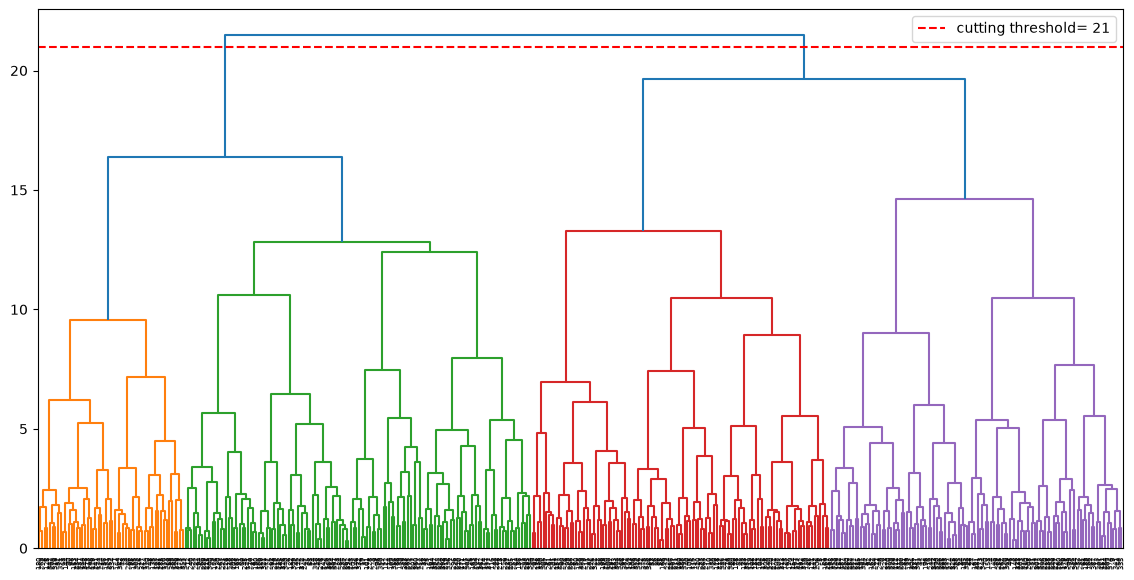

In [38]:
plt.figure(figsize=(14, 7))
dendrogram(Z)

plt.axhline(
    y=21,
    color="red",
    linestyle="--",
    label="cutting threshold= 21"
)
plt.legend()
plt.show()

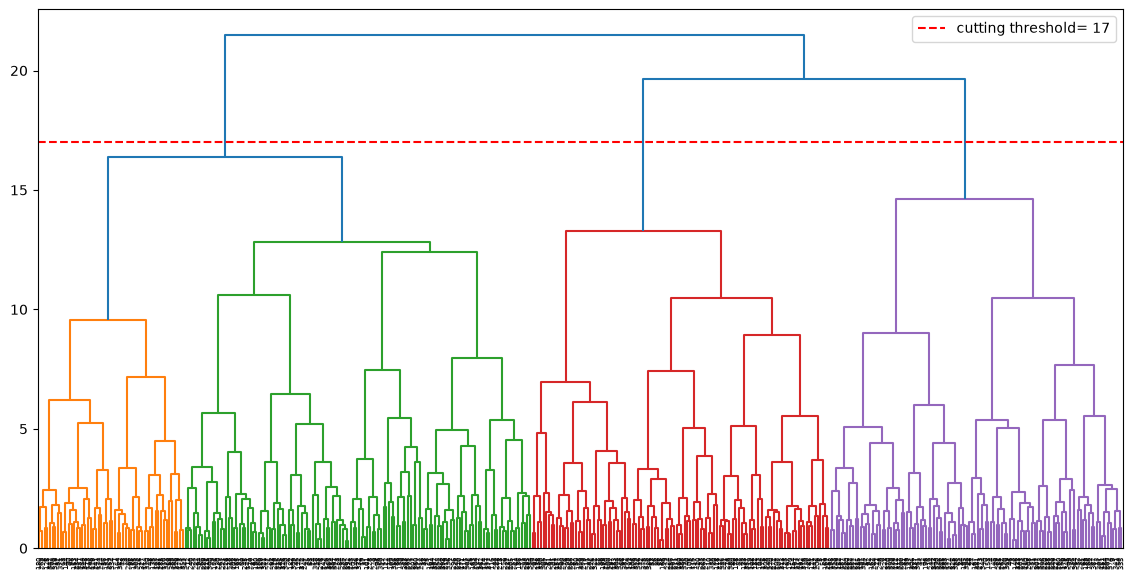

In [39]:
plt.figure(figsize=(14, 7))
dendrogram(Z)

plt.axhline(
    y=17,
    color="red",
    linestyle="--",
    label="cutting threshold= 17"
)
plt.legend()
plt.show()